# Dataset 2 — EDA and Preliminary Feature Screening

**Project:** Daily Lifestyle Habits and Student Stress Prediction  
**Scope:** data ingestion, cleaning checks, visualization, screening and a provisional shortlist. **No trained prediction models.**

**Workflow:** Understand data → Check quality → Plot target → Review **all candidate factors** → Record preliminary decisions → Plot shortlisted factors.

**Target:** `Current_stress_level` (self-reported 1–5). Weak visual relationships are **not** proof that a variable has no predictive value.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

## 1. Load CSV and inspect

In [2]:
df2 = pd.read_csv("../data/raw/dataset2.csv")
print("Rows, columns:", df2.shape)
display(df2.head())
df2.info()
display(df2.describe(include="all").T.head(31))

Rows, columns: (300, 31)


,Q Number,Age,Gender,Type_of_residence,Current_CGPA,Financial_stress_level,Discipline_Program,Current_Study_Year,Current_stress_level,Depression_level,Anxiety_level,Overwhelmed_by_academic_workload,Used_counseling_services,Family_history_of_health_issues,Strength_of_social_support,Focus_on_academic_tasks,Average_sleep_duration_per_night,Bedtime_on_regular_nights,Sleep_quality,Difficulty_falling_asleep,Use_of_electronic_devices_before_bed,Night_time_caffeine_consumption,Daytime_sleepiness_during_classes,Hours_spent_daily_on_academic_activities,Physical_activity_per_week,Diet_quality,Smoking_or_substance_use,Chronic_illness,Awareness_of_recommended_sleep,Skipped_class_due_to_poor_sleep_or_stress,Impact_of_stress_on_academic_performance
0,1,19,Female,On-Campus,3.85,1,NFE,3,5,1,4,Never,Occasionally,Yes,High,Always,5-6 hrs,After 12 AM,Good,Rarely,Yes,Yes,Rarely,>4 hrs,Moderate,Average,Occasionally,No,Yes,No,Somewhat Positive
1,2,18,Male,Off-Campus,3.96,4,CIVIL,3,1,1,1,Rarely,Frequently,Yes,Moderate,Rarely,<5 hrs,After 12 AM,Average,Almost Always,Yes,Yes,Often,1-2 hrs,Low,Good,Occasionally,No,No,No,Somewhat Positive
2,3,28,Male,Off-Campus,3.23,1,NFE,2,5,1,3,Often,Never,No,High,Sometimes,7-8 hrs,After 12 AM,Poor,Sometimes,No,No,Never,3-4 hrs,Low,Average,Never,No,No,Yes,No Impact
3,4,19,Female,With Family,4.00,1,NFE,3,5,2,1,Sometimes,Never,No,Moderate,Often,5-6 hrs,After 12 AM,Poor,Almost Always,Yes,No,Rarely,3-4 hrs,High,Poor,Never,No,Yes,Yes,Very Positive
4,5,21,Female,Off-Campus,3.42,3,CSE,4,3,5,1,Never,Occasionally,No,High,Always,5-6 hrs,After 12 AM,Average,Almost Always,Yes,Yes,Rarely,<1 hrs,Moderate,Good,Occasionally,No,Yes,Yes,Somewhat Negative


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 31 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Q Number                                   300 non-null    int64  
 1   Age                                        300 non-null    int64  
 2   Gender                                     300 non-null    object 
 3   Type_of_residence                          300 non-null    object 
 4   Current_CGPA                               300 non-null    float64
 5   Financial_stress_level                     300 non-null    int64  
 6   Discipline_Program                         300 non-null    object 
 7   Current_Study_Year                         300 non-null    int64  
 8   Current_stress_level                       300 non-null    int64  
 9   Depression_level                           300 non-null    int64  
 10  Anxiety_level             

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Q Number,300.0,NaN,NaN,NaN,150.5,86.746758,1.0,75.75,150.5,225.25,300.0
Age,300.0,NaN,NaN,NaN,21.876667,3.102721,18.0,19.0,21.0,23.0,35.0
Gender,300,2,Female,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type_of_residence,300,3,On-Campus,125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_CGPA,300.0,NaN,NaN,NaN,3.464533,0.288595,2.7,3.23,3.485,3.6525,4.0
Financial_stress_level,300.0,NaN,NaN,NaN,2.69,1.456355,1.0,1.0,3.0,4.0,5.0
Discipline_Program,300,7,LLB,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current_Study_Year,300.0,NaN,NaN,NaN,2.886667,0.918314,1.0,2.0,3.0,4.0,4.0
Current_stress_level,300.0,NaN,NaN,NaN,2.546667,1.424049,1.0,1.0,2.0,4.0,5.0
Depression_level,300.0,NaN,NaN,NaN,2.343333,1.372979,1.0,1.0,2.0,3.0,5.0


## 2. Data-quality checks

In [3]:
print("Missing values per column:")
display(df2.isna().sum().to_frame("missing"))
print("Exact duplicate rows:", df2.duplicated().sum())
print("Unique stress levels:", sorted(df2["Current_stress_level"].dropna().unique()))

Missing values per column:


,missing
Q Number,0
Age,0
Gender,0
Type_of_residence,0
Current_CGPA,0
Financial_stress_level,0
Discipline_Program,0
Current_Study_Year,0
Current_stress_level,0
Depression_level,0


Exact duplicate rows: 0
Unique stress levels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


## 3. Stress-level distribution

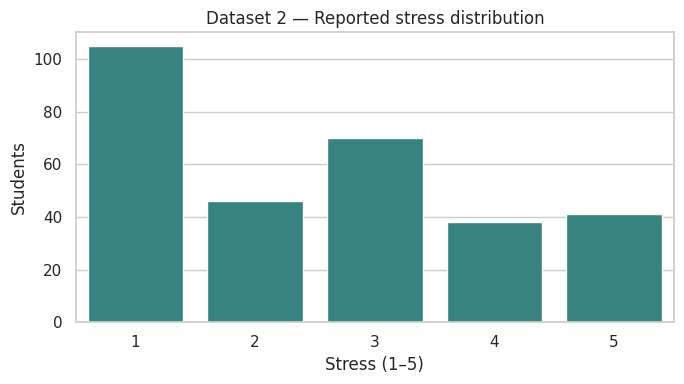

In [4]:
stress_col = "Current_stress_level"
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df2, x=stress_col, order=[1, 2, 3, 4, 5], ax=ax, color="#2c8f8b")
ax.set(title="Dataset 2 — Reported stress distribution", xlabel="Stress (1–5)", ylabel="Students")
plt.tight_layout(); plt.show()

## 4. Review every survey factor against stress

Each categorical factor is displayed as a **row-percentage heatmap**. Each row totals about 100%. The numeric/identifier fields are handled separately below. Charts illustrate patterns, not causation. Plots can be numerous; this is intentional for systematic screening.

In [5]:
# Exclude target, respondent ID, and continuous CGPA (handled separately).
excluded = {"Q Number", "Current_stress_level", "Current_CGPA"}
candidate_factors = [c for c in df2.columns if c not in excluded]
print("Factors to review:", len(candidate_factors))
print(candidate_factors)

Factors to review: 28
['Age', 'Gender', 'Type_of_residence', 'Financial_stress_level', 'Discipline_Program', 'Current_Study_Year', 'Depression_level', 'Anxiety_level', 'Overwhelmed_by_academic_workload', 'Used_counseling_services', 'Family_history_of_health_issues', 'Strength_of_social_support', 'Focus_on_academic_tasks', 'Average_sleep_duration_per_night', 'Bedtime_on_regular_nights', 'Sleep_quality', 'Difficulty_falling_asleep', 'Use_of_electronic_devices_before_bed', 'Night_time_caffeine_consumption', 'Daytime_sleepiness_during_classes', 'Hours_spent_daily_on_academic_activities', 'Physical_activity_per_week', 'Diet_quality', 'Smoking_or_substance_use', 'Chronic_illness', 'Awareness_of_recommended_sleep', 'Skipped_class_due_to_poor_sleep_or_stress', 'Impact_of_stress_on_academic_performance']


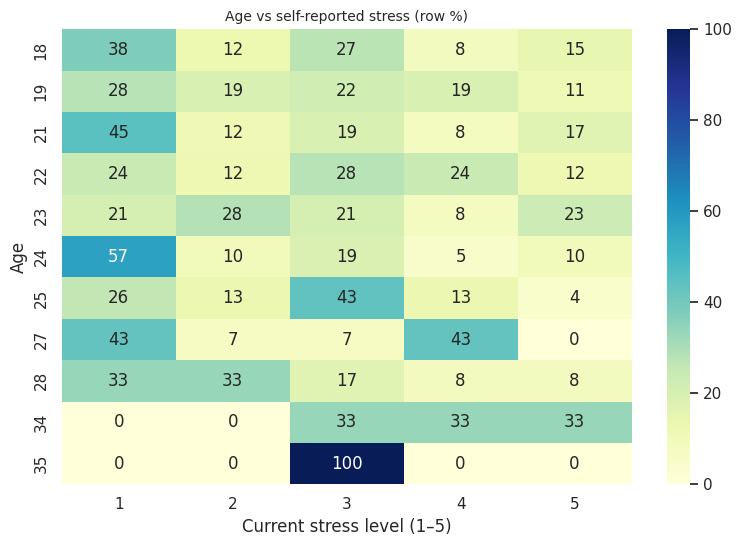

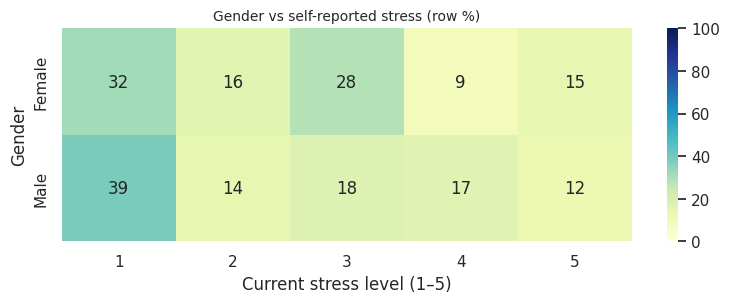

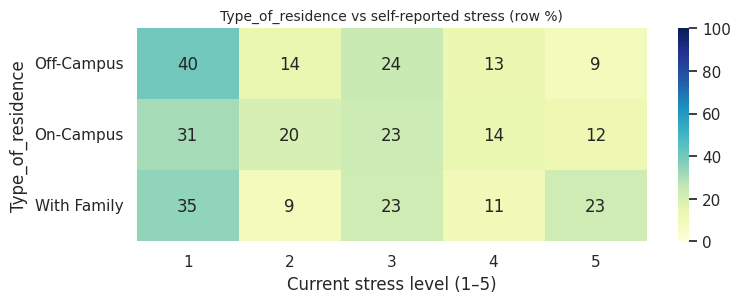

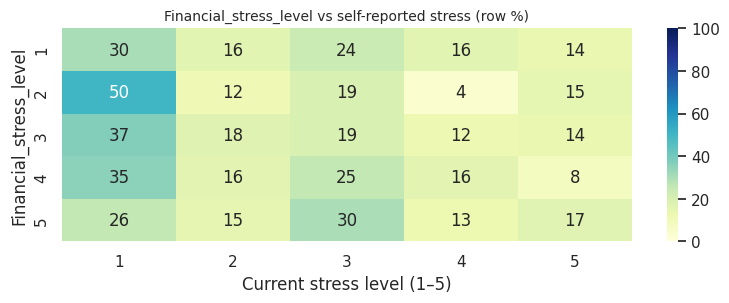

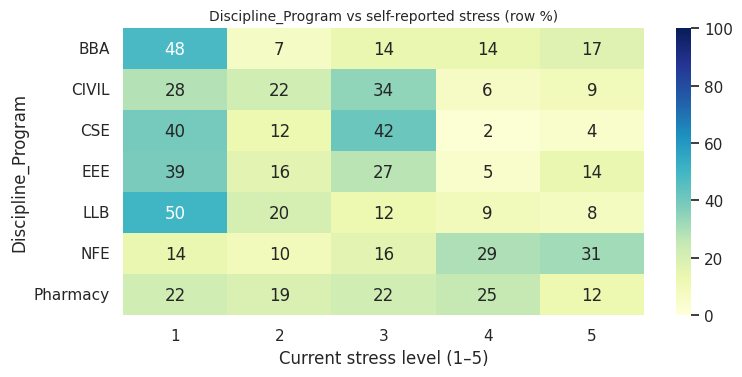

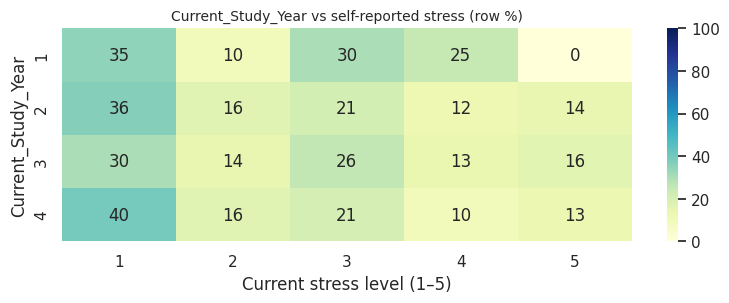

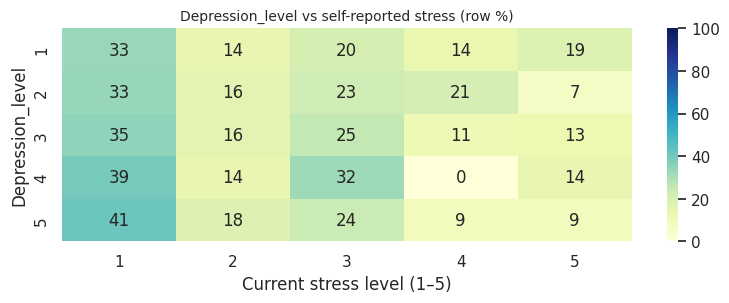

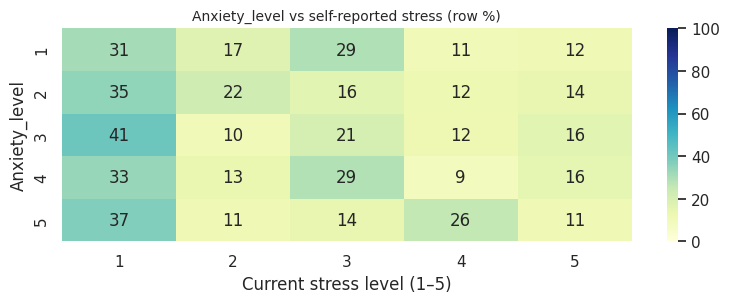

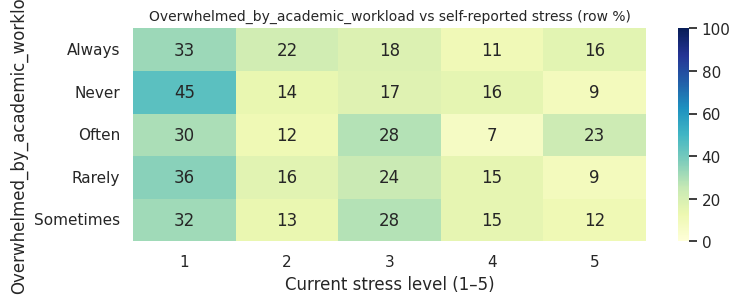

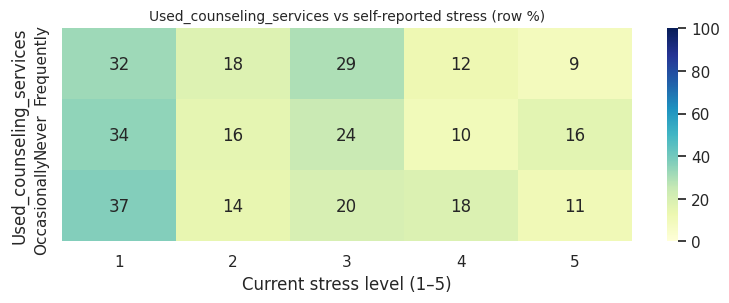

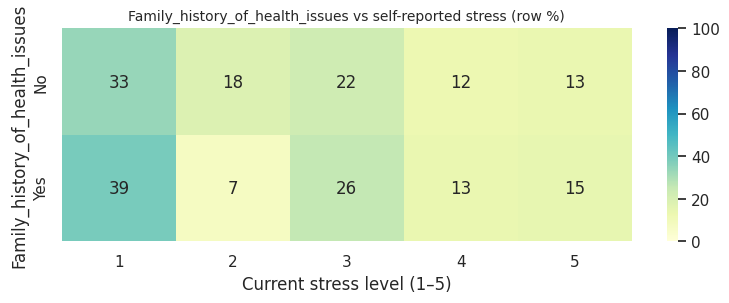

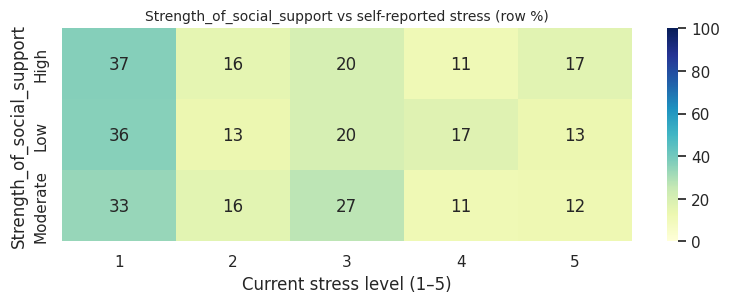

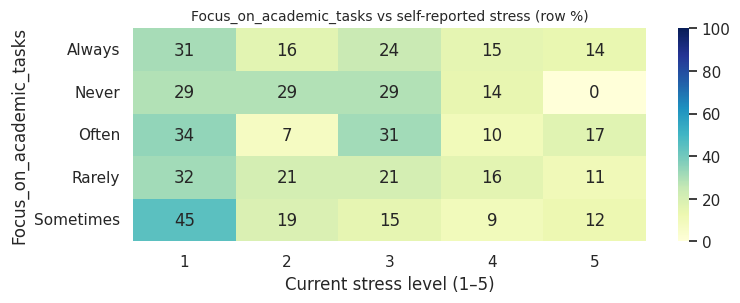

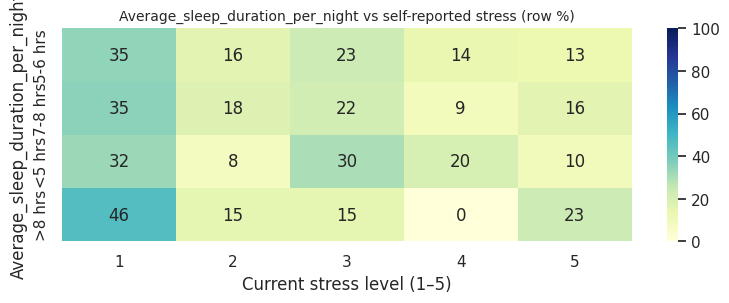

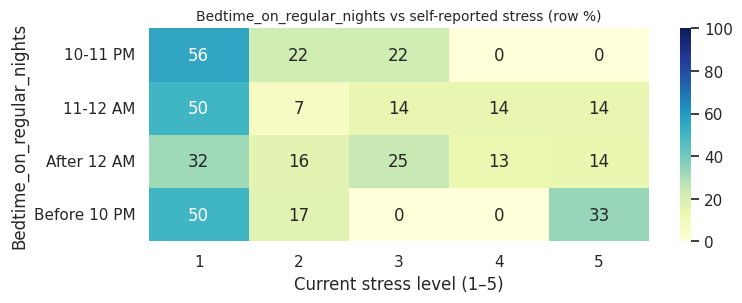

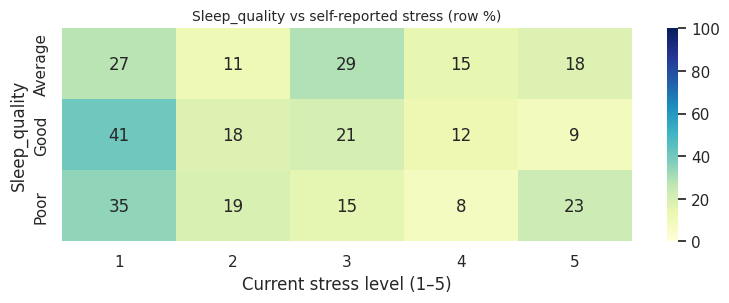

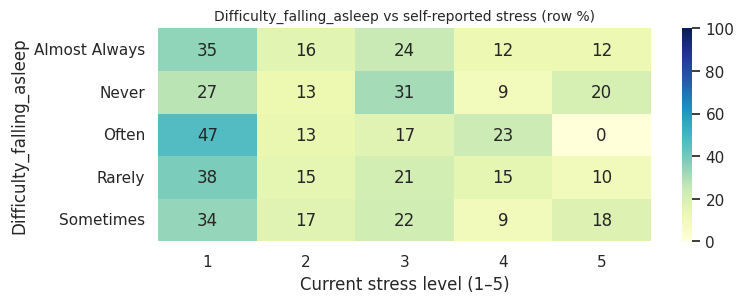

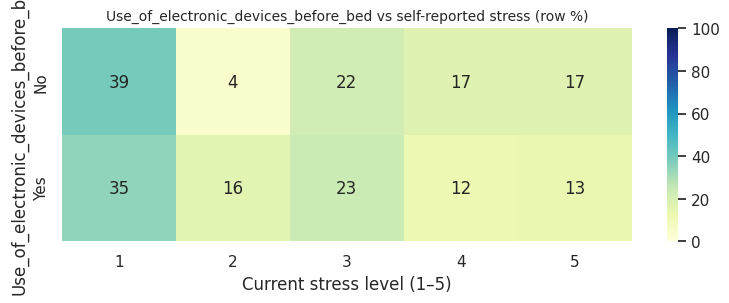

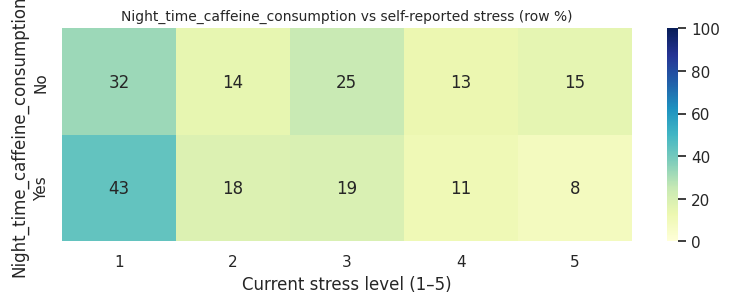

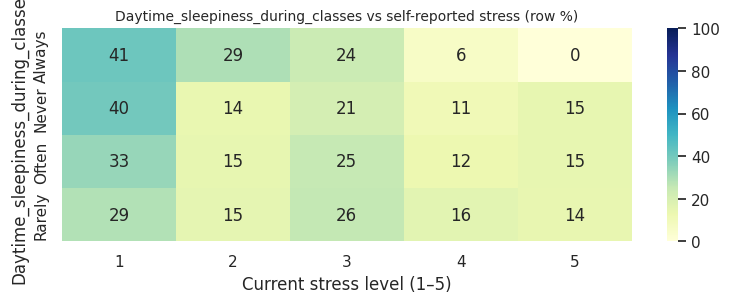

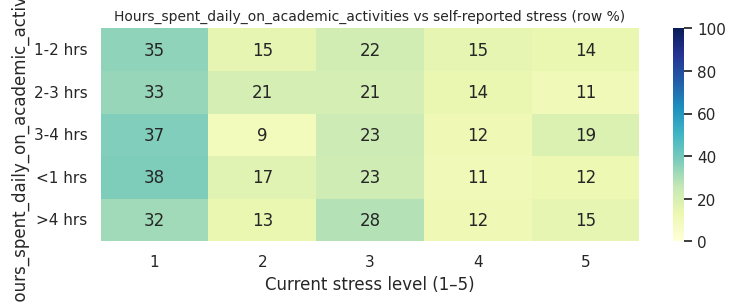

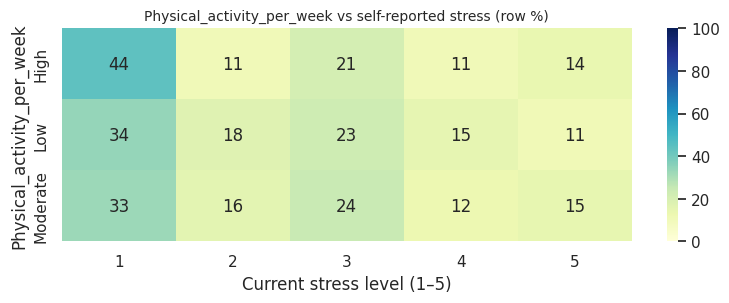

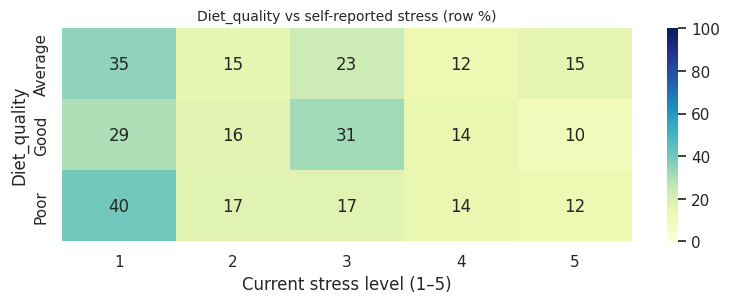

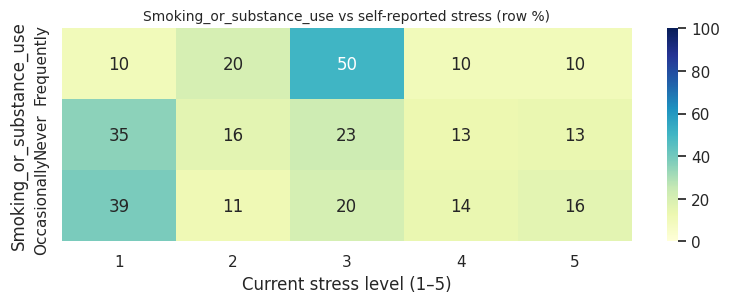

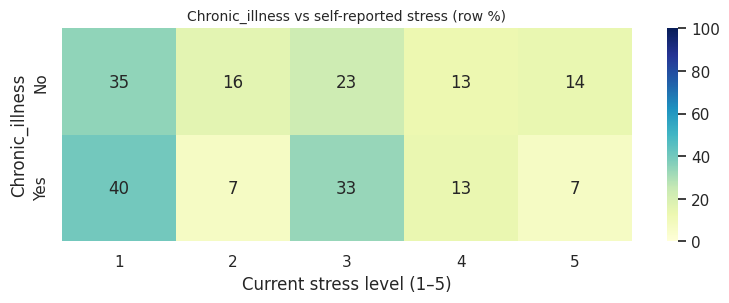

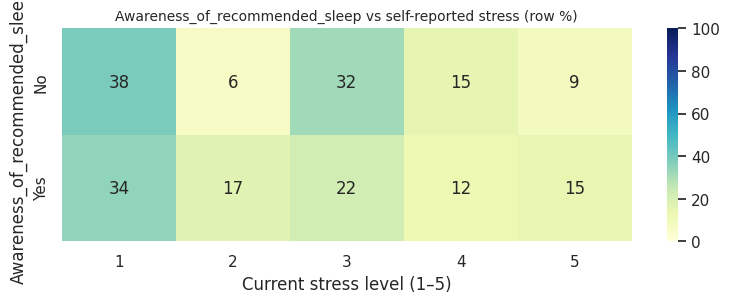

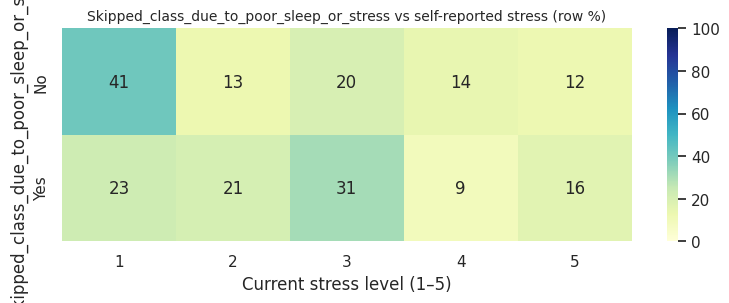

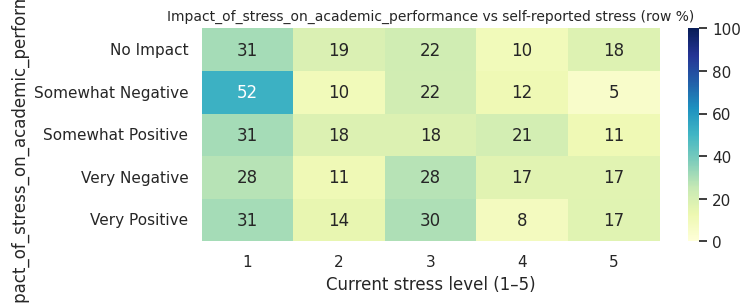

In [6]:
for factor in candidate_factors:
    counts = pd.crosstab(df2[factor], df2[stress_col])
    if counts.empty:
        continue
    pct = counts.div(counts.sum(axis=1), axis=0).mul(100)
    pct = pct.reindex(columns=[1, 2, 3, 4, 5], fill_value=0)
    fig_height = max(3.2, min(10, 1.0 + 0.42 * len(pct)))
    plt.figure(figsize=(8, fig_height))
    sns.heatmap(pct, annot=True, fmt=".0f", cmap="YlGnBu", vmin=0, vmax=100)
    plt.title(f"{factor} vs self-reported stress (row %)", fontsize=10)
    plt.xlabel("Current stress level (1–5)");plt.ylabel(factor)
    plt.tight_layout();plt.show()

## 5. Optional CGPA visualization (continuous variable)

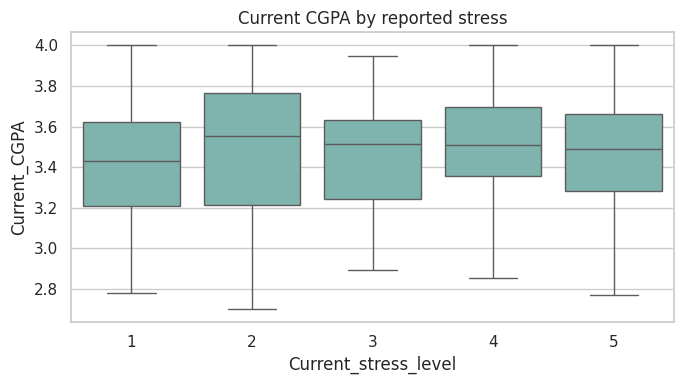

In [7]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df2, x=stress_col, y="Current_CGPA", order=[1,2,3,4,5], color="#76bcb5")
plt.title("Current CGPA by reported stress")
plt.tight_layout();plt.show()

## 6. Document a preliminary review

The default decisions below are **based on the project goal and target-leakage concerns, not a statistical ranking**. After examining the heatmaps, edit each reason/decision based on observed patterns. Do not delete the original data.

In [8]:
core_features = [
    "Average_sleep_duration_per_night",
    "Sleep_quality",
    "Hours_spent_daily_on_academic_activities",
    "Physical_activity_per_week",
    "Use_of_electronic_devices_before_bed",
    "Night_time_caffeine_consumption",
    "Diet_quality"
]
extra_to_review = ["Overwhelmed_by_academic_workload", "Strength_of_social_support", "Financial_stress_level", "Difficulty_falling_asleep", "Bedtime_on_regular_nights"]
review = pd.DataFrame({"Factor": candidate_factors,
                       "Decision": ["Shortlist" if c in core_features else "Explore further" if c in extra_to_review else "Lower priority" for c in candidate_factors],
                       "Reason": ["Direct lifestyle/academic project input" if c in core_features else "Relevant extra factor; verify interpretation" if c in extra_to_review else "Not in initial seven-factor project scope; inspect heatmap" for c in candidate_factors]})
display(review)
print("Excluded from predictors: Q Number (ID), target itself; examine distress/outcome fields with caution")

,Factor,Decision,Reason
0,Age,Lower priority,Not in initial seven-factor project scope; ins...
1,Gender,Lower priority,Not in initial seven-factor project scope; ins...
2,Type_of_residence,Lower priority,Not in initial seven-factor project scope; ins...
3,Financial_stress_level,Explore further,Relevant extra factor; verify interpretation
4,Discipline_Program,Lower priority,Not in initial seven-factor project scope; ins...
5,Current_Study_Year,Lower priority,Not in initial seven-factor project scope; ins...
6,Depression_level,Lower priority,Not in initial seven-factor project scope; ins...
7,Anxiety_level,Lower priority,Not in initial seven-factor project scope; ins...
8,Overwhelmed_by_academic_workload,Explore further,Relevant extra factor; verify interpretation
9,Used_counseling_services,Lower priority,Not in initial seven-factor project scope; ins...


Excluded from predictors: Q Number (ID), target itself; examine distress/outcome fields with caution


## 7. Create shortlist without removing original columns

In [9]:
selected_features_d2 = core_features.copy()
target_d2 = "Current_stress_level"
selected_df_d2 = df2[selected_features_d2 + [target_d2]].copy()
print(selected_df_d2.shape)
display(selected_df_d2.head())

(300, 8)


,Average_sleep_duration_per_night,Sleep_quality,Hours_spent_daily_on_academic_activities,Physical_activity_per_week,Use_of_electronic_devices_before_bed,Night_time_caffeine_consumption,Diet_quality,Current_stress_level
0,5-6 hrs,Good,>4 hrs,Moderate,Yes,Yes,Average,5
1,<5 hrs,Average,1-2 hrs,Low,Yes,Yes,Good,1
2,7-8 hrs,Poor,3-4 hrs,Low,No,No,Average,5
3,5-6 hrs,Poor,3-4 hrs,High,Yes,No,Poor,5
4,5-6 hrs,Average,<1 hrs,Moderate,Yes,Yes,Good,3


## 8. Focused charts for the seven shortlisted features

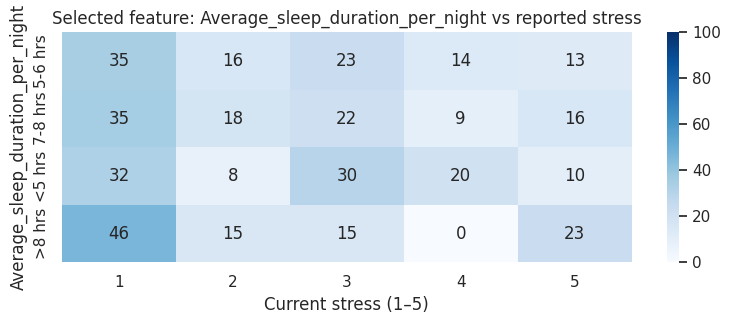

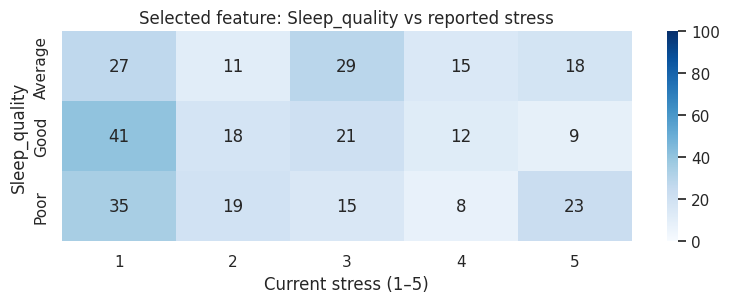

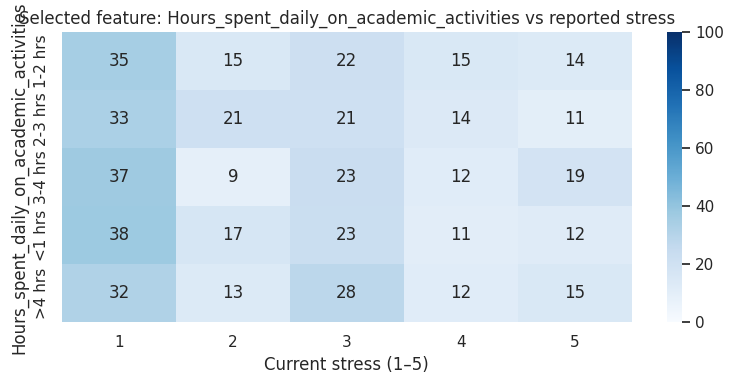

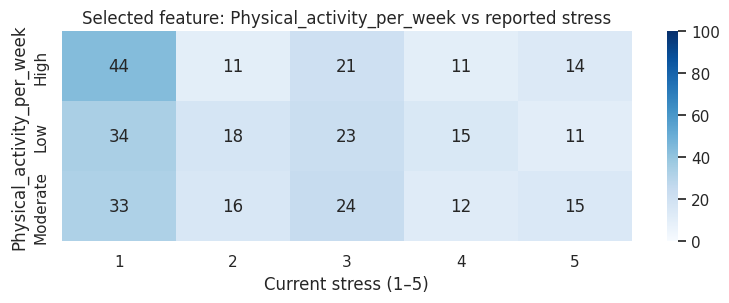

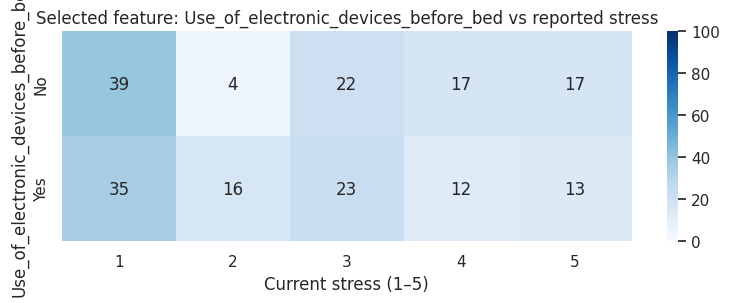

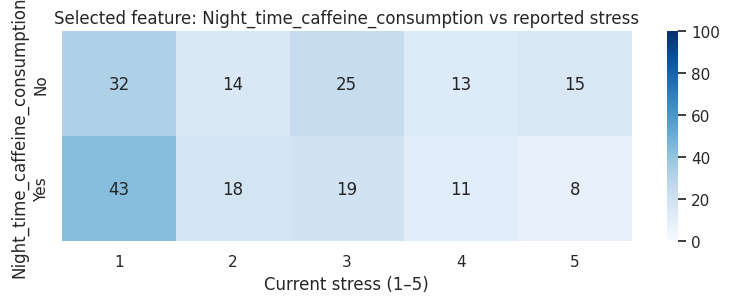

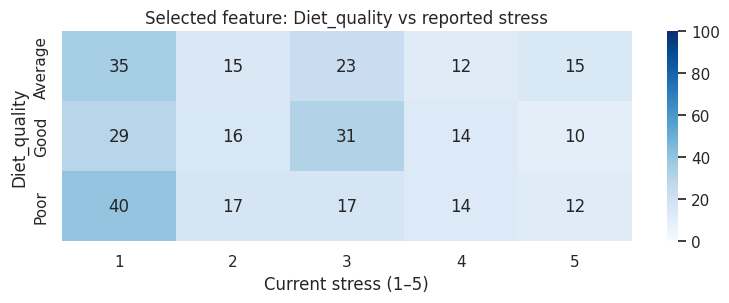

In [10]:
for factor in selected_features_d2:
    counts = pd.crosstab(df2[factor], df2[target_d2])
    percentages = counts.div(counts.sum(axis=1), axis=0).mul(100)
    percentages = percentages.reindex(columns=[1,2,3,4,5],fill_value=0)
    plt.figure(figsize=(8,max(3.2,0.6*len(percentages)+1)))
    sns.heatmap(percentages,annot=True,fmt=".0f",cmap="Blues",vmin=0,vmax=100)
    plt.title(f"Selected feature: {factor} vs reported stress")
    plt.xlabel("Current stress (1–5)");plt.ylabel(factor)
    plt.tight_layout();plt.show()

## 9. Findings and limitations

- **300 records, 31 columns**. The target is independently self-reported current stress (1–5), not calculated from the selected lifestyle factors.
- Compare the patterns across the heatmaps; many differences appear modest. **A heatmap alone cannot prove that a factor is useless or causal.**
- Row percentages can be misleading when there are very few students in a category; consult the underlying counts.
- The seven columns are a **provisional shortlist**, not final features. Keep the full DataFrame to enable later testing.
- **Next stage:** compare candidate datasets, then train and evaluate a model once covered in the course.